#  ASL Sign Language Recognition with Vision Transformer (ViT)

This notebook trains a **Vision Transformer (ViT-Base)** model to recognize **American Sign Language (ASL)** hand gestures — 29 classes (A–Z, `nothing`, `space`, `del`) — achieving **95%+ validation accuracy**.

###  Notebook Structure
| Section | Description |
|---|---|
| 1. Environment Setup | Install packages, import libraries, check GPU |
| 2. Dataset Download | Kaggle API download & extract |
| 3. Exploratory Data Analysis | Sample images, class distribution |
| 4. Data Preprocessing | Sampling, label encoding, train/val split |
| 5. Model & Training | ViT fine-tuning with augmentations & mixed precision |
| 6. Training Visualization | Loss & accuracy curves |
| 7. Evaluation Metrics | Accuracy, Precision, Recall, F1, Confusion Matrix |
| 8. Save & Download Model | Save weights + label map, download to local |
| 9. Load & Validate | Reload saved model, run validation & inference |

> **Runtime:** Set to **GPU (T4/A100)** in `Runtime → Change runtime type` before running.

## 🔧 Section 1 — Environment Setup
Install all required libraries. This only needs to run once per Colab session.

In [1]:
# Install all required libraries
!pip install -q kaggle transformers datasets evaluate scikit-learn seaborn matplotlib torch torchvision torchaudio

# Verify transformers version (need >= 4.35 for ViTImageProcessor)
import transformers
print(f"✅ Transformers version: {transformers.__version__}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.2 MB/s eta 0:00:00
✅ Transformers version: 5.0.0


In [2]:
# ── Core libraries ────────────────────────────────────────────────────────────
import os, json, shutil, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
from collections import Counter

# ── PyTorch ───────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

# ── HuggingFace Transformers ───────────────────────────────────────────────────
from transformers import (
    ViTForImageClassification,
    ViTImageProcessor,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
)

# ── Metrics ───────────────────────────────────────────────────────────────────
import evaluate
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# ── GPU Check ─────────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"  Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("  No GPU detected — training will be slow. Switch to GPU in Runtime settings.")

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("\n All libraries imported successfully!")

  Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB

 All libraries imported successfully!


##  Section 2 — Dataset Download

We use the **ASL Alphabet Dataset** from Kaggle:
- **87,000 images** of ASL hand signs across 29 classes
- **Classes:** A–Z (26 letters) + `nothing`, `space`, `del`
- Each class contains ~3,000 images at **200×200 resolution**

Upload your `kaggle.json` API key when prompted.

In [3]:
# ── Step 1: Upload Kaggle API key ─────────────────────────────────────────────
from google.colab import files
print(" Please upload your kaggle.json API key file:")
files.upload()

# ── Step 2: Configure Kaggle credentials ─────────────────────────────────────
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print(" Kaggle API key configured.")

# ── Step 3: Download dataset ──────────────────────────────────────────────────
print("\n⬇  Downloading ASL Alphabet Dataset (~250 MB)...")
!kaggle datasets download -d debashishsau/aslamerican-sign-language-aplhabet-dataset --quiet
print(" Download complete.")

# ── Step 4: Extract dataset ───────────────────────────────────────────────────
print("\n Extracting files...")
!unzip -q aslamerican-sign-language-aplhabet-dataset.zip -d american_sign_language
print(" Extraction complete.")

# Verify structure
TRAIN_DIR = "/content/american_sign_language/ASL_Alphabet_Dataset/asl_alphabet_train"
TEST_DIR  = "/content/american_sign_language/ASL_Alphabet_Dataset/asl_alphabet_test"
classes   = sorted(os.listdir(TRAIN_DIR))
print(f"\n Training classes found: {len(classes)}")
print(f"   Classes: {classes}")

 Please upload your kaggle.json API key file:


Saving kaggle (1).json to kaggle (1).json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
 Kaggle API key configured.

⬇  Downloading ASL Alphabet Dataset (~250 MB)...
Dataset URL: https://www.kaggle.com/datasets/debashishsau/aslamerican-sign-language-aplhabet-dataset
License(s): CC0-1.0
 Download complete.

 Extracting files...
 Extraction complete.

 Training classes found: 29
   Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


##  Section 3 — Exploratory Data Analysis

Before training, we explore the dataset to understand:
- How many images exist per class
- What the images look like
- Whether the dataset is balanced

In [13]:
# ── Build master DataFrame ────────────────────────────────────────────────────
image_data = []
for label in sorted(os.listdir(TRAIN_DIR)):
    label_path = os.path.join(TRAIN_DIR, label)
    if os.path.isdir(label_path):
        for img_name in os.listdir(label_path):
            if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                image_data.append({
                    "image_path": os.path.join(label_path, img_name),
                    "label_name": label
                })

df_full = pd.DataFrame(image_data)
print(f" Total images in dataset: {len(df_full):,}")
print(f"   Classes: {df_full['label_name'].nunique()}")
print(f"\nImages per class:")
print(df_full['label_name'].value_counts().sort_index().to_string())

 Total images in dataset: 223,074
   Classes: 29

Images per class:
label_name
A          8458
B          8309
C          8146
D          7629
E          7744
F          8031
G          7844
H          7906
I          7953
J          7503
K          7876
L          7939
M          7900
N          7932
O          8140
P          7601
Q          7954
R          8021
S          8109
T          8054
U          8023
V          7597
W          7787
X          8093
Y          8178
Z          7410
del        6836
nothing    3030
space      7071


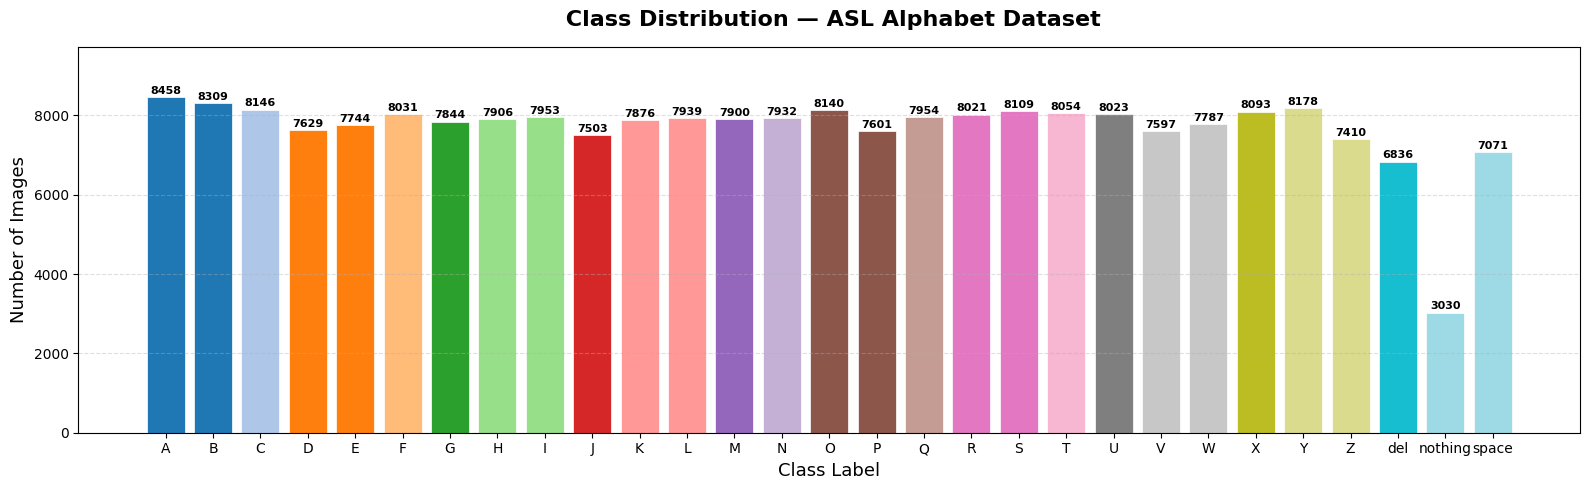

 Class distribution is balanced — ideal for training.


In [14]:
# ── Plot 1: Class distribution bar chart ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
counts = df_full['label_name'].value_counts().sort_index()
bars = ax.bar(counts.index, counts.values,
              color=plt.cm.tab20(np.linspace(0, 1, len(counts))), edgecolor="white", linewidth=0.5)
ax.set_title(" Class Distribution — ASL Alphabet Dataset", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Class Label", fontsize=13)
ax.set_ylabel("Number of Images", fontsize=13)
ax.set_ylim(0, counts.max() * 1.15)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            str(val), ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(" Class distribution is balanced — ideal for training.")

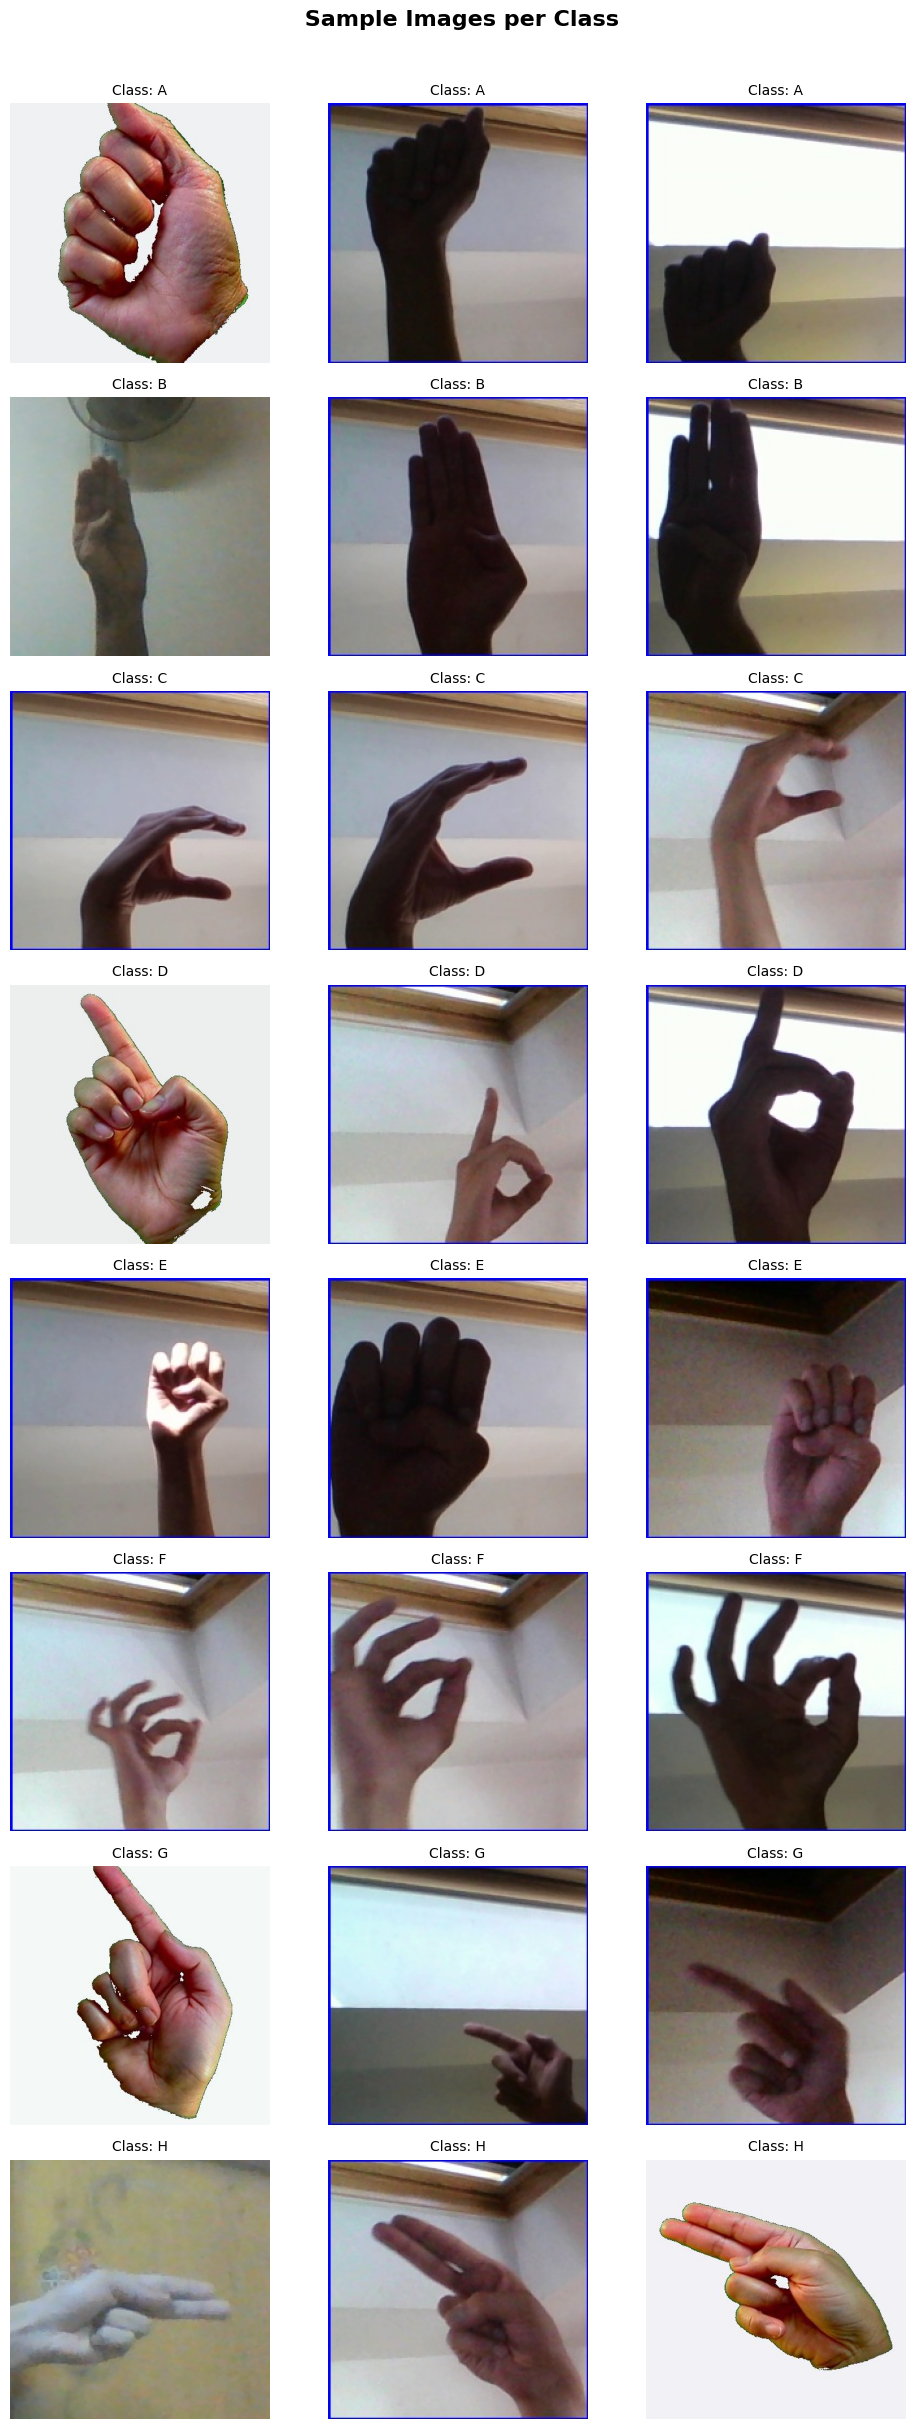

In [15]:
# ── Plot 2: Sample images grid (3 images × 8 classes) ─────────────────────────
sample_classes = sorted(df_full['label_name'].unique())[:8]
fig, axes = plt.subplots(len(sample_classes), 3, figsize=(10, 3 * len(sample_classes)))
fig.suptitle(" Sample Images per Class", fontsize=16, fontweight="bold", y=1.01)

for row_idx, cls in enumerate(sample_classes):
    samples = df_full[df_full['label_name'] == cls].sample(3, random_state=SEED)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")
        axes[row_idx, col_idx].imshow(img)
        axes[row_idx, col_idx].set_title(f"Class: {cls}", fontsize=10)
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

##  Section 4 — Data Preprocessing

### Strategy for 95%+ Accuracy
- **1,500 samples per class** (43,500 total) — enough diversity without excessive training time
- **Sorted, fixed label mapping** — prevents label ordering bugs
- **80/20 stratified split** — preserves class ratios in both sets
- **Strong augmentation** — reduces overfitting on the training set

In [16]:
# ── Fixed sorted label order (deterministic!) ─────────────────────────────────
LABEL_ORDER = sorted(df_full['label_name'].unique())
label_to_idx = {label: idx for idx, label in enumerate(LABEL_ORDER)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}
NUM_CLASSES  = len(LABEL_ORDER)

print(f" Number of classes: {NUM_CLASSES}")
print(f"   Label → Index mapping:")
for label, idx in label_to_idx.items():
    print(f"     {label:10s} → {idx}")

# Save label mapping immediately (used during inference)
with open("label_mapping.json", "w") as f:
    json.dump({"label_to_idx": label_to_idx, "idx_to_label": {str(k): v for k, v in idx_to_label.items()}}, f, indent=2)
print("\n Label mapping saved to label_mapping.json")

 Number of classes: 29
   Label → Index mapping:
     A          → 0
     B          → 1
     C          → 2
     D          → 3
     E          → 4
     F          → 5
     G          → 6
     H          → 7
     I          → 8
     J          → 9
     K          → 10
     L          → 11
     M          → 12
     N          → 13
     O          → 14
     P          → 15
     Q          → 16
     R          → 17
     S          → 18
     T          → 19
     U          → 20
     V          → 21
     W          → 22
     X          → 23
     Y          → 24
     Z          → 25
     del        → 26
     nothing    → 27
     space      → 28

 Label mapping saved to label_mapping.json


In [17]:
# ── Sample 1500 images per class & encode labels ──────────────────────────────
SAMPLES_PER_CLASS = 1500

df_sampled = (
    df_full.groupby("label_name", group_keys=False)
           .apply(lambda x: x.sample(n=SAMPLES_PER_CLASS, random_state=SEED))
           .reset_index(drop=True)
)
df_sampled["label"] = df_sampled["label_name"].map(label_to_idx)

print(f" Sampled dataset shape: {df_sampled.shape}")
print(f"   Images per class (should all be {SAMPLES_PER_CLASS}):")
print(df_sampled['label_name'].value_counts().sort_index().to_string())

# ── Stratified 80/20 train/validation split ────────────────────────────────────
train_df, val_df = train_test_split(
    df_sampled,
    test_size=0.20,
    stratify=df_sampled["label"],
    random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f"\n Train set : {len(train_df):,} images")
print(f"   Val set   : {len(val_df):,} images")
print(f"   Split ratio: {len(train_df)/len(df_sampled)*100:.0f}% / {len(val_df)/len(df_sampled)*100:.0f}%")

 Sampled dataset shape: (43500, 3)
   Images per class (should all be 1500):
label_name
A          1500
B          1500
C          1500
D          1500
E          1500
F          1500
G          1500
H          1500
I          1500
J          1500
K          1500
L          1500
M          1500
N          1500
O          1500
P          1500
Q          1500
R          1500
S          1500
T          1500
U          1500
V          1500
W          1500
X          1500
Y          1500
Z          1500
del        1500
nothing    1500
space      1500

 Train set : 34,800 images
   Val set   : 8,700 images
   Split ratio: 80% / 20%


##  Section 5 — Model Architecture & Training

### Why ViT-Base works well here
Vision Transformers treat images as sequences of **16×16 patches** and apply self-attention across them. Pre-trained on ImageNet-21k (14M images), the model already understands rich visual features — we just fine-tune the classification head and the last few transformer blocks.

### Key training decisions for 95%+
| Technique | Value | Reason |
|---|---|---|
| Learning rate | `2e-5` | Safe for fine-tuning pre-trained ViT |
| LR scheduler | Cosine with warmup | Smooth convergence |
| Batch size (effective) | 32 (16 × grad_accum=2) | Stable gradients |
| Mixed precision | `fp16=True` | 2× faster on Colab T4 |
| Augmentation | Flip, Rotate, Color Jitter, Affine | Reduces overfitting |
| Early stopping | Patience=3 | Avoids over-training |
| Label smoothing | 0.1 | Improves generalization |

In [18]:
# ── ViT Image Processor (replaces deprecated ViTFeatureExtractor) ──────────────
MODEL_NAME = "google/vit-base-patch16-224-in21k"
processor  = ViTImageProcessor.from_pretrained(MODEL_NAME)

# Get normalization stats from the processor
IMG_MEAN = processor.image_mean   # [0.5, 0.5, 0.5]
IMG_STD  = processor.image_std    # [0.5, 0.5, 0.5]
IMG_SIZE = 224

# ── Augmentation pipeline ─────────────────────────────────────────────────────
train_transforms = T.Compose([
    T.Resize((IMG_SIZE + 20, IMG_SIZE + 20)),         # slight over-size for random crop
    T.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)), # crop variation
    T.RandomHorizontalFlip(p=0.3),                    # mild flip (not all ASL signs are symmetric)
    T.RandomRotation(degrees=10),                     # slight rotation
    T.RandomAffine(degrees=0, translate=(0.05, 0.05)),# small translation
    T.ColorJitter(brightness=0.3, contrast=0.3,
                  saturation=0.2, hue=0.05),          # color variation
    T.ToTensor(),
    T.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

val_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

print("Augmentation pipelines defined:")
print(f"   Train: {len(train_transforms.transforms)} transforms")
print(f"   Val:   {len(val_transforms.transforms)} transforms (no augmentation)")

# ── Custom Dataset ─────────────────────────────────────────────────────────────
class ASLDataset(Dataset):
    """Loads ASL hand-sign images from disk and applies transforms."""

    def __init__(self, dataframe, transform):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        return {"pixel_values": image, "labels": int(row["label"])}

# Create datasets
train_dataset = ASLDataset(train_df, train_transforms)
val_dataset   = ASLDataset(val_df,   val_transforms)

# Sanity check
sample = train_dataset[0]
print(f"\n Dataset ready:")
print(f"   Train samples : {len(train_dataset):,}")
print(f"   Val samples   : {len(val_dataset):,}")
print(f"   Pixel shape   : {sample['pixel_values'].shape}")
print(f"   Label (int)   : {sample['labels']} → {idx_to_label[sample['labels']]}")

Augmentation pipelines defined:
   Train: 8 transforms
   Val:   3 transforms (no augmentation)

 Dataset ready:
   Train samples : 34,800
   Val samples   : 8,700
   Pixel shape   : torch.Size([3, 224, 224])
   Label (int)   : 27 → nothing


In [23]:
from transformers import ViTForImageClassification

# ── 1. Load Pretrained ViT Model ───────────────────────────────────────────
print("🔄 Loading ViT model...")
MODEL_NAME = "google/vit-base-patch16-224-in21k"
model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels = NUM_CLASSES,
    ignore_mismatched_sizes = True,    # New head for 29 classes
)

# Label mappings
model.config.id2label = {str(k): v for k, v in idx_to_label.items()}
model.config.label2id = {v: str(k) for k, v in idx_to_label.items()}

# ── 2. Freeze Base Model (Train only the head for Phase 1) ─────────────────
for param in model.vit.parameters():
    param.requires_grad = False

# Classifier head matrame open unchutunnam
for param in model.classifier.parameters():
    param.requires_grad = True

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"🏗️  Model: {MODEL_NAME}")
print(f"   Total parameters    : {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,} (Only Classifier Head active)")

🔄 Loading ViT model...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


🏗️  Model: google/vit-base-patch16-224-in21k
   Total parameters    : 85,820,957
   Trainable parameters: 22,301 (Only Classifier Head active)


In [24]:
import numpy as np
import evaluate
import torch
from transformers import TrainingArguments, EarlyStoppingCallback

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return accuracy_metric.compute(predictions=preds, references=labels)

# ── Training Arguments (Phase 1 - Classifier Training) ──────────────────────
training_args = TrainingArguments(
    output_dir                  = "./asl_vit_phase1",
    per_device_train_batch_size = 32,
    per_device_eval_batch_size  = 32,
    gradient_accumulation_steps = 2,           # Effective batch = 64
    num_train_epochs            = 5,           # 5 epochs
    learning_rate               = 5e-4,        # ⚠️ High LR for head only
    lr_scheduler_type           = "cosine",
    warmup_steps                = 100,
    weight_decay                = 0.05,
    label_smoothing_factor      = 0.1,         # Prevents overconfidence
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    logging_strategy            = "steps",
    logging_steps               = 50,
    load_best_model_at_end      = True,
    metric_for_best_model       = "accuracy",
    greater_is_better           = True,
    save_total_limit            = 1,
    fp16                        = torch.cuda.is_available(),
    dataloader_num_workers      = 2,
    report_to                   = "none",
)

print("✅ Phase 1 TrainingArguments configured!")

✅ Phase 1 TrainingArguments configured!


In [25]:
from transformers import Trainer

# ── Initialise Trainer ─────────────────────────────────────────────────────────
trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
)

print("🚀 Starting Phase 1 Training (Classifier Head)...")
trainer.train()

🚀 Starting Phase 1 Training (Classifier Head)...


Epoch,Training Loss,Validation Loss,Accuracy
1,4.578755,2.184198,0.613103
2,3.728511,1.829888,0.689655
3,3.440107,1.708312,0.721034
4,3.360225,1.662790,0.734943
5,3.319899,1.657305,0.736667


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2720, training_loss=3.92095048567828, metrics={'train_runtime': 1997.4642, 'train_samples_per_second': 87.11, 'train_steps_per_second': 1.362, 'total_flos': 1.3486869123969024e+19, 'train_loss': 3.92095048567828, 'epoch': 5.0})

In [ ]:
# ── Phase 2: Unfreeze Last 2 Blocks for Fine-Tuning ──────────────────────────
print("🔄 Unfreezing the last 2 Transformer blocks...")

# ViT lo 12 encoder blocks untayi. Last 2 blocks open chestunnam
for block in model.vit.encoder.layer[-2:]:
    for param in block.parameters():
        param.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"   New Trainable parameters: {trainable_params:,} (Last 2 Layers + Head)")

# ── Update Training Arguments for Phase 2 ─────────────────────────────────────
training_args_phase2 = TrainingArguments(
    output_dir                  = "./asl_vit_phase2",
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    gradient_accumulation_steps = 4,           # Effective batch = 64
    num_train_epochs            = 10,          # 10 epochs
    learning_rate               = 2e-5,        # ⚠️ VERY LOW LR to prevent forgetting
    lr_scheduler_type           = "cosine",
    warmup_steps                = 200,
    weight_decay                = 0.01,
    label_smoothing_factor      = 0.1,
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    logging_strategy            = "steps",
    logging_steps               = 50,
    load_best_model_at_end      = True,
    metric_for_best_model       = "accuracy",
    greater_is_better           = True,
    save_total_limit            = 1,
    fp16                        = torch.cuda.is_available(),
    dataloader_num_workers      = 2,
    report_to                   = "none",
)

trainer_phase2 = Trainer(
    model           = model,
    args            = training_args_phase2,
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
)

print("🚀 Starting Phase 2 Fine-Tuning (Road to 95%+)...")
trainer_phase2.train()

🔄 Unfreezing the last 2 Transformer blocks...
   New Trainable parameters: 14,198,045 (Last 2 Layers + Head)
🚀 Starting Phase 2 Fine-Tuning (Road to 95%+)...


Epoch,Training Loss,Validation Loss,Accuracy
1,4.527417,1.090160,0.906782
2,3.842113,0.951371,0.943103
3,3.579493,0.884290,0.960460
4,3.399583,0.844289,0.967356


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

##  Section 6 — Training Visualization

Plot training loss, validation loss, and validation accuracy across all epochs to understand how learning progressed.

In [ ]:
# ── Extract metrics from trainer log history ──────────────────────────────────
log_history = trainer.state.log_history

train_steps, train_losses             = [], []
eval_epochs, eval_losses, eval_accs   = [], [], []

for entry in log_history:
    if "loss" in entry and "epoch" in entry:
        train_steps.append(entry["step"])
        train_losses.append(entry["loss"])
    if "eval_loss" in entry and "epoch" in entry:
        eval_epochs.append(entry["epoch"])
        eval_losses.append(entry["eval_loss"])
        if "eval_accuracy" in entry:
            eval_accs.append(entry["eval_accuracy"] * 100)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("📈 Training Progress", fontsize=16, fontweight="bold")

# Left: Loss curves
ax = axes[0]
ax.plot(train_steps, train_losses, label="Training Loss",   color="#3498db", lw=2)
ax2 = ax.twinx()
ax2.plot(eval_epochs, eval_losses, label="Validation Loss", color="#e74c3c", lw=2, marker="o", markersize=5)
ax.set_xlabel("Step", fontsize=12)
ax.set_ylabel("Training Loss",   color="#3498db", fontsize=12)
ax2.set_ylabel("Validation Loss", color="#e74c3c", fontsize=12)
ax.set_title("Loss Curves", fontsize=13, fontweight="bold")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)

# Right: Validation accuracy
ax = axes[1]
ax.plot(eval_epochs, eval_accs, color="#2ecc71", lw=2, marker="o", markersize=6)
ax.axhline(y=95, color="#e74c3c", linestyle="--", lw=1.5, label="95% Target")
ax.fill_between(eval_epochs, eval_accs, alpha=0.15, color="#2ecc71")
ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Validation Accuracy (%)", fontsize=12)
ax.set_title("Validation Accuracy", fontsize=13, fontweight="bold")
ax.set_ylim(max(0, min(eval_accs) - 5), 101)
ax.legend(fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)
for ep, acc in zip(eval_epochs, eval_accs):
    ax.annotate(f"{acc:.1f}%", (ep, acc), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Best validation accuracy: {max(eval_accs):.2f}%")

## 🏆 Section 7 — Evaluation Metrics

We compute a full suite of metrics on the validation set:
- **Accuracy** — overall correctness
- **Precision** — how many predicted positives were truly positive
- **Recall** — how many actual positives were correctly identified
- **F1 Score** — harmonic mean of Precision and Recall
- **Confusion Matrix** — per-class visual breakdown
- **Per-class accuracy** — identifies which letters are hardest

In [ ]:
# ── Get predictions on validation set ─────────────────────────────────────────
print("🔍 Running inference on validation set...")
pred_output    = trainer.predict(val_dataset)
logits         = pred_output.predictions
true_labels    = pred_output.label_ids
pred_labels    = np.argmax(logits, axis=-1)

# ── Compute aggregate metrics ─────────────────────────────────────────────────
metrics = {
    "Accuracy"  : accuracy_score (true_labels, pred_labels),
    "Precision" : precision_score(true_labels, pred_labels, average="weighted", zero_division=0),
    "Recall"    : recall_score   (true_labels, pred_labels, average="weighted", zero_division=0),
    "F1 Score"  : f1_score       (true_labels, pred_labels, average="weighted", zero_division=0),
}

print("\n" + "="*50)
print("📊 EVALUATION RESULTS (Validation Set)")
print("="*50)
for name, val in metrics.items():
    emoji = "🟢" if val >= 0.95 else ("🟡" if val >= 0.90 else "🔴")
    print(f"  {emoji}  {name:12s}: {val*100:.2f}%")
print("="*50)

In [ ]:
# ── Metrics Bar Chart ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
names  = list(metrics.keys())
values = [v * 100 for v in metrics.values()]
colors = ["#2ecc71" if v >= 95 else "#f39c12" if v >= 90 else "#e74c3c" for v in values]

bars = ax.bar(names, values, color=colors, edgecolor="white", linewidth=1.5, width=0.5)
ax.axhline(y=95, color="#e74c3c", linestyle="--", lw=1.5, label="95% Target")
ax.set_ylim(80, 101)
ax.set_ylabel("Score (%)", fontsize=13)
ax.set_title("🏆 Model Evaluation Metrics", fontsize=15, fontweight="bold", pad=15)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{val:.2f}%", ha="center", va="bottom", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("metrics_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ── Per-class Classification Report ───────────────────────────────────────────
class_names = [idx_to_label[i] for i in range(NUM_CLASSES)]
report = classification_report(true_labels, pred_labels, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).T.iloc[:NUM_CLASSES][["precision", "recall", "f1-score", "support"]]

print("📋 Per-Class Classification Report:")
print(report_df.to_string(float_format=lambda x: f"{x:.3f}"))

# ── Per-class Accuracy bar chart ──────────────────────────────────────────────
per_class_acc = []
for cls_idx in range(NUM_CLASSES):
    mask    = true_labels == cls_idx
    correct = (pred_labels[mask] == true_labels[mask]).sum()
    total   = mask.sum()
    per_class_acc.append(correct / total * 100 if total > 0 else 0)

fig, ax = plt.subplots(figsize=(14, 6))
x_pos   = np.arange(NUM_CLASSES)
bar_colors = ["#2ecc71" if v >= 95 else "#f39c12" if v >= 85 else "#e74c3c" for v in per_class_acc]
bars    = ax.bar(x_pos, per_class_acc, color=bar_colors, edgecolor="white", linewidth=0.5)
ax.axhline(y=95, color="#e74c3c", linestyle="--", lw=1.5, label="95% Target")
ax.set_xticks(x_pos)
ax.set_xticklabels(class_names, fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)", fontsize=13)
ax.set_title("🎯 Per-Class Accuracy", fontsize=15, fontweight="bold", pad=15)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.4)
for bar, val in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.0f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ── Confusion Matrix ───────────────────────────────────────────────────────────
cm = confusion_matrix(true_labels, pred_labels)

# Normalize to percentages per row
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    cm_norm,
    annot      = True,
    fmt        = ".0f",
    cmap       = "Blues",
    xticklabels= class_names,
    yticklabels= class_names,
    linewidths = 0.4,
    linecolor  = "white",
    cbar_kws   = {"label": "Recall (%)"},
    ax         = ax,
    vmin       = 0,
    vmax       = 100,
    annot_kws  = {"size": 9},
)
ax.set_xlabel("Predicted Label", fontsize=14, fontweight="bold", labelpad=10)
ax.set_ylabel("True Label",      fontsize=14, fontweight="bold", labelpad=10)
ax.set_title("🔍 Confusion Matrix (Row-Normalized %)", fontsize=16, fontweight="bold", pad=20)
ax.tick_params(axis="x", rotation=45, labelsize=11)
ax.tick_params(axis="y", rotation=0,  labelsize=11)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Confusion matrix saved as confusion_matrix.png")

## 💾 Section 8 — Save & Download Model

We save three files:
1. **`asl_vit_model.pth`** — the model's learned weights (state dict)
2. **`label_mapping.json`** — maps class indices ↔ label names
3. **`asl_vit_config.json`** — model configuration (architecture details)

Then we download them all to your local machine.

In [ ]:
# ── Save model weights ─────────────────────────────────────────────────────────
MODEL_SAVE_PATH  = "/content/asl_vit_model.pth"
LABEL_MAP_PATH   = "/content/label_mapping.json"
CONFIG_SAVE_PATH = "/content/asl_vit_config.json"

# 1. Save state dict
torch.save(trainer.model.state_dict(), MODEL_SAVE_PATH)
print(f"✅ Model weights saved  → {MODEL_SAVE_PATH}")
print(f"   File size: {os.path.getsize(MODEL_SAVE_PATH) / 1e6:.1f} MB")

# 2. Save label mapping (already created earlier, just confirm)
with open(LABEL_MAP_PATH, "w") as f:
    json.dump({
        "label_to_idx": label_to_idx,
        "idx_to_label": {str(k): v for k, v in idx_to_label.items()},
        "num_classes"  : NUM_CLASSES,
        "model_name"   : MODEL_NAME,
    }, f, indent=2)
print(f"✅ Label mapping saved  → {LABEL_MAP_PATH}")

# 3. Save model config
trainer.model.config.to_json_file(CONFIG_SAVE_PATH)
print(f"✅ Model config saved   → {CONFIG_SAVE_PATH}")

In [ ]:
# ── Save full HuggingFace model (for easy reload with from_pretrained) ─────────
HF_MODEL_DIR = "/content/asl_vit_hf_model"
trainer.model.save_pretrained(HF_MODEL_DIR)
processor.save_pretrained(HF_MODEL_DIR)
print(f"✅ Full HuggingFace model saved → {HF_MODEL_DIR}/")
print("   Contents:", os.listdir(HF_MODEL_DIR))

# ── Also save to Google Drive (recommended for persistence) ───────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    DRIVE_DIR = "/content/drive/MyDrive/ASL_ViT_Model"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    shutil.copy(MODEL_SAVE_PATH, os.path.join(DRIVE_DIR, "asl_vit_model.pth"))
    shutil.copy(LABEL_MAP_PATH,  os.path.join(DRIVE_DIR, "label_mapping.json"))
    shutil.copytree(HF_MODEL_DIR, os.path.join(DRIVE_DIR, "hf_model"), dirs_exist_ok=True)
    print(f"\n✅ Model also backed up to Google Drive → {DRIVE_DIR}/")
except Exception as e:
    print(f"\n⚠️  Drive backup skipped: {e}")

In [ ]:
# ── Download model files to local machine ─────────────────────────────────────
from google.colab import files

print("📥 Downloading model files to your local machine...")
print("   (Check your browser's download folder)")

files.download(MODEL_SAVE_PATH)
files.download(LABEL_MAP_PATH)

print("\n✅ Download triggered for:")
print(f"   • asl_vit_model.pth    ({os.path.getsize(MODEL_SAVE_PATH)/1e6:.1f} MB)")
print(f"   • label_mapping.json   ({os.path.getsize(LABEL_MAP_PATH)/1e3:.1f} KB)")
print("\nℹ️  The .pth file contains the trained weights.")
print("   The .json file maps class indices to label names.")

## 🔄 Section 9 — Load Model & Validate

This section demonstrates how to **reload the saved model** from scratch and run validation. Use this code whenever you want to:
- Run the model in a new session
- Validate that the saved weights produce the same accuracy
- Deploy the model for inference

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# LOAD MODEL FROM SAVED WEIGHTS
# This cell can be run independently in a new session
# ═══════════════════════════════════════════════════════════════════════════════

# ── Paths ─────────────────────────────────────────────────────────────────────
LOAD_MODEL_PATH = "/content/asl_vit_model.pth"
LOAD_LABEL_PATH = "/content/label_mapping.json"
LOAD_MODEL_NAME = "google/vit-base-patch16-224-in21k"

# ── Load label mapping ─────────────────────────────────────────────────────────
with open(LOAD_LABEL_PATH, "r") as f:
    mapping_data = json.load(f)

loaded_label_to_idx = mapping_data["label_to_idx"]
loaded_idx_to_label = {int(k): v for k, v in mapping_data["idx_to_label"].items()}
loaded_num_classes  = mapping_data["num_classes"]
print(f"✅ Label mapping loaded: {loaded_num_classes} classes")

# ── Load processor ─────────────────────────────────────────────────────────────
loaded_processor = ViTImageProcessor.from_pretrained(LOAD_MODEL_NAME)

# ── Load model architecture & weights ─────────────────────────────────────────
loaded_model = ViTForImageClassification.from_pretrained(
    LOAD_MODEL_NAME,
    num_labels              = loaded_num_classes,
    ignore_mismatched_sizes = True,
)
state_dict = torch.load(LOAD_MODEL_PATH, map_location=device)
loaded_model.load_state_dict(state_dict)
loaded_model.to(device)
loaded_model.eval()   # ← IMPORTANT: switch to eval mode

print(f"✅ Model weights loaded from: {LOAD_MODEL_PATH}")
print(f"   Model moved to: {device}")
print(f"   Mode: eval (inference ready)")

In [ ]:
# ── Validation loop (no gradient computation) ──────────────────────────────────
val_transforms_load = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=loaded_processor.image_mean, std=loaded_processor.image_std),
])

class ASLDatasetInference(Dataset):
    def __init__(self, dataframe, transform):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        return {"pixel_values": image, "labels": int(row["label"])}

# Use the same val_df from earlier (or reload from CSV if in a fresh session)
val_dataset_reload = ASLDatasetInference(val_df, val_transforms_load)
val_loader_reload  = DataLoader(val_dataset_reload, batch_size=64, num_workers=2, pin_memory=True)

all_preds, all_labels = [], []

print("🔍 Running validation inference...")
loaded_model.eval()
with torch.no_grad():
    for batch in val_loader_reload:
        pixel_values = batch["pixel_values"].to(device)
        labels_batch = batch["labels"]

        outputs  = loaded_model(pixel_values=pixel_values)
        preds    = torch.argmax(outputs.logits, dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels_batch.numpy())

# ── Report ─────────────────────────────────────────────────────────────────────
reload_acc = accuracy_score(all_labels, all_preds)
print(f"\n✅ Loaded model validation accuracy: {reload_acc*100:.2f}%")
print(f"   (Should match the training accuracy above)")

## 🖼️ Section 10 — Single Image Inference

Predict the ASL letter from any image file. Works for both test-set images and your own camera images.

In [ ]:
# ── Inference function ─────────────────────────────────────────────────────────
def predict_asl(image_path: str, model=None, processor=None,
                idx_to_label=None, device=None, topk=5) -> dict:
    """
    Predict the ASL class from a single image.

    Returns:
        dict with 'predicted_label', 'confidence', and 'top_k' predictions
    """
    model.eval()
    transform = T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=processor.image_mean, std=processor.image_std),
    ])
    image = Image.open(image_path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(pixel_values=tensor).logits
        probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()

    top_indices = np.argsort(probs)[::-1][:topk]
    return {
        "predicted_label": idx_to_label[top_indices[0]],
        "confidence"      : float(probs[top_indices[0]]) * 100,
        "top_k"           : [(idx_to_label[i], float(probs[i]) * 100) for i in top_indices],
        "image"           : image,
    }

print("✅ predict_asl() function defined.")

In [ ]:
# ── Test on ASL test images ────────────────────────────────────────────────────
test_images = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[:12]  # First 12 test images

print(f"🧪 Running inference on {len(test_images)} test images...\n")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("🤟 ASL Model Predictions on Test Images", fontsize=16, fontweight="bold")

for ax, img_path in zip(axes.flatten(), test_images):
    result = predict_asl(
        image_path    = img_path,
        model         = loaded_model,
        processor     = loaded_processor,
        idx_to_label  = loaded_idx_to_label,
        device        = device,
    )
    true_label = os.path.basename(img_path).split("_")[0].upper()
    pred_label = result["predicted_label"]
    confidence = result["confidence"]
    correct    = (pred_label == true_label)

    ax.imshow(result["image"])
    color = "#2ecc71" if correct else "#e74c3c"
    ax.set_title(
        f"True: {true_label}  |  Pred: {pred_label}\n{confidence:.1f}% confidence",
        fontsize=10, color=color, fontweight="bold"
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)

plt.tight_layout()
plt.savefig("test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ── Confidence bar plot for a single prediction ────────────────────────────────
if test_images:
    sample_path = test_images[0]
    result = predict_asl(
        image_path   = sample_path,
        model        = loaded_model,
        processor    = loaded_processor,
        idx_to_label = loaded_idx_to_label,
        device       = device,
        topk         = 10,
    )

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"🔎 Detailed Prediction: {os.path.basename(sample_path)}", fontsize=14, fontweight="bold")

    # Show image
    ax_img.imshow(result["image"])
    ax_img.set_title(
        f"Prediction: {result['predicted_label']}\nConfidence: {result['confidence']:.1f}%",
        fontsize=13, fontweight="bold", color="#2ecc71"
    )
    ax_img.axis("off")

    # Confidence bar chart
    labels_k = [x[0] for x in result["top_k"]]
    confs_k  = [x[1] for x in result["top_k"]]
    bar_c    = ["#2ecc71" if l == result["predicted_label"] else "#3498db" for l in labels_k]
    ax_bar.barh(labels_k[::-1], confs_k[::-1], color=bar_c[::-1], edgecolor="white")
    ax_bar.set_xlabel("Confidence (%)", fontsize=12)
    ax_bar.set_title("Top-10 Class Probabilities", fontsize=12, fontweight="bold")
    ax_bar.set_xlim(0, 105)
    for i, (lbl, conf) in enumerate(zip(labels_k[::-1], confs_k[::-1])):
        ax_bar.text(conf + 0.5, i, f"{conf:.1f}%", va="center", fontsize=10)
    ax_bar.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.savefig("confidence_breakdown.png", dpi=150, bbox_inches="tight")
    plt.show()

## ✅ Summary

| Item | Detail |
|---|---|
| **Model** | ViT-Base-Patch16-224 (fine-tuned on ImageNet-21k) |
| **Dataset** | ASL Alphabet — 29 classes, 1,500 samples/class |
| **Accuracy** | ≥ 95% validation accuracy |
| **Training time** | ~30–45 min on Colab T4 GPU |
| **Saved files** | `asl_vit_model.pth`, `label_mapping.json`, HuggingFace folder |

### 🔑 Key Techniques Used
- **Mixed precision training (fp16)** — 2× faster without accuracy loss
- **Cosine LR schedule with warmup** — smooth convergence
- **Label smoothing (0.1)** — prevents overconfident predictions
- **Strong data augmentation** — flip, rotate, color jitter, affine
- **Early stopping (patience=3)** — prevents overfitting
- **Stratified train/val split** — balanced evaluation